# Prueba de estrés de liquidez inversa y las pruebas de validación de liquidez

**Pregunta:** ¿Cuánto más rápido que las tablas LiST Adverso y Extremo deben salir los depósitos del banco que quebró en 2023 para que sobreviva solo 30 días, y cuándo se niega el motor a dar un número?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 04 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar la prueba de estrés de liquidez inversa como una pregunta ("¿cuánto más rápido deben salir los depósitos para que el banco sobreviva solo 30 días?") y responderla con el motor como un multiplicador de las tasas de fuga;
- explicar el tope del multiplicador (ninguna tasa sobre 1), la propiedad de umbral de la solución y las tres razones por las que el motor rechaza una meta;
- leer las pruebas de validación del paquete de liquidez: el viaje de ida y vuelta del solucionador, la monotonía del período de supervivencia y la identidad de la NLP;
- leer el costo de una supervivencia más corta como una curva de multiplicadores, y el acantilado de la posición como un diagnóstico.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
# Etiquetas en español de los semáforos de las pruebas de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `data/derived/C16/reverse-stress.json`: la tensión inversa de tres bases (LiST Adverso, LiST Extremo y la corrida rápida) con una meta de 30 días: el tope, la curva del período de supervivencia frente al multiplicador, el multiplicador resuelto con su viaje de ida y vuelta y las filas de prueba.
- `data/derived/C16/list-adverse.json` y `data/derived/C16/list-extreme.json`: las escaleras (segmentos, series diarias) con las que se reconstruyen los escenarios de las dos bases LiST, como en el notebook 04.

La pregunta viene de la escalera de modelos de liquidez de la investigación (tensión de liquidez inversa, peldaño 5 de la escalera: el multiplicador de fuga con el que el período de supervivencia cae bajo una meta, por ejemplo 30 días), y de la práctica supervisora de someter a tensión en muchos escenarios, cortos y prolongados, individualmente y en combinación (BCBS, 2008, Principio 10). Los montos están en miles de USD.

In [2]:
# Cargar los tres documentos versionados (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("reverse-stress", "list-adverse", "list-extreme"):
    path = ROOT / "data" / "derived" / "C16" / f"{name}.json"
    documents[name] = json.loads(path.read_text(encoding="utf-8"))
    baked = documents[name]["provenance"]["riskvalidation_version"]
    print(name, "| calculado con riskvalidation", baked, "| instalado", rv.__version__)

reverse_doc = documents["reverse-stress"]
outputs = reverse_doc["outputs"]
bases = {base["base_id"]: base for base in outputs["bases"]}
print("meta del documento (días):", outputs["target"]["days"])

reverse-stress | calculado con riskvalidation 1.0.1 | instalado 1.0.1
list-adverse | calculado con riskvalidation 1.0.1 | instalado 1.0.1
list-extreme | calculado con riskvalidation 1.0.1 | instalado 1.0.1
meta del documento (días): 30


## Método

### Paso 1: el escenario y un CBC que el motor pueda usar

La tensión inversa toma un escenario base (segmentos con una clase y un saldo inicial, notebook 04) y un CBC diario. El solucionador del motor calcula la NLP a partir del CBC y de las salidas conductuales de los segmentos, y no toma entradas ni salidas contractuales. La escalera del documento sí las tiene, así que el documento le entrega al solucionador un **CBC efectivo** que absorbe ambas y deja intacta la NLP de la escalera:

$$\mathrm{CBC}^{\mathrm{eff}}(t) = \mathrm{CBC}(t) + \sum_{s \le t} I(s) - \sum_{s \le t} O_{\text{contractual}}(s), \qquad \mathrm{NLP}(t) = \mathrm{CBC}^{\mathrm{eff}}(t) - \sum_{s \le t} O_{\text{segments}}(s)$$

Esta es una convención del documento del producto (el motor no la impone), y la identidad es verificable: la celda siguiente compone los escenarios Adverso y Extremo a partir de los segmentos versionados, construye el CBC efectivo y corre la prueba `liq.nlp_identity`, cuyo estadístico es el mayor residuo absoluto entre la NLP del motor a partir del CBC efectivo y la NLP versionada de la escalera.

In [3]:
# Componer las dos bases LiST, construir el CBC efectivo y probar la identidad de la NLP
from riskvalidation.liquidity.scenarios import compose_scenario, list_scenario
from riskvalidation.validation.liquidity import nlp_identity

conventions = outputs["conventions"]
rows = {row["variant"]: row for row in conventions["variant_scenarios"]["rows"]}
built = {}
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme")):
    lad = documents[base_id]["outputs"]["path"]["ladder"]
    row = rows[base_id]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    args = (row["scenario_family"], row["phase"], list_scenario(severity))
    scenario = compose_scenario(*args, segments, row["horizon_days"])
    segment_outflows = scenario.outflows().sum(axis=0)
    contractual = np.array(lad["total_outflows"]) - segment_outflows
    effective_cbc = np.array(lad["cbc_total"]) + np.cumsum(lad["total_inflows"]) - np.cumsum(contractual)
    no_inflows = np.zeros_like(segment_outflows)
    identity = nlp_identity(effective_cbc, segment_outflows, no_inflows, np.array(lad["nlp"]))
    built[base_id] = (scenario, effective_cbc)
    print(base_id, "| prueba de identidad, mayor residuo:", round(identity.statistic, 9), LIGHTS[identity.light.value])

list-adverse | prueba de identidad, mayor residuo: 7e-09 verde
list-extreme | prueba de identidad, mayor residuo: 3e-08 verde


### Paso 2: el multiplicador, su tope y la curva del período de supervivencia

Un multiplicador $m \ge 1$ escala la tasa diaria de cada segmento, con la tasa limitada a 1 como máximo (una tasa no puede ser más que todo el stock):

$$q_s'(d) = \min\bigl(m\, q_s(d),\; 1\bigr), \qquad m_{\max} = \frac{1}{\max\{\, q_s(d) : q_s(d) < 1 \,\}}$$

El tope $m_{\max}$ es el multiplicador con el que la mayor tasa bajo 1 llega a 1; más allá, escalar ya no cambia el segmento que importa, así que un punto más allá del tope se rechaza. Una tasa que ya está en 1 (el segmento financiero) se mantiene en 1. El período de supervivencia $\mathrm{SP}(m)$ es no creciente en $m$, y "sobrevive el horizonte" cuenta como más largo que cualquier día. `max_multiplier` da el tope y `survival_vs_multiplier` da el período de supervivencia bajo cada multiplicador de una grilla; la grilla del documento es una convención declarada (1, 1,25, 1,5, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144). La celda siguiente calcula ambas bases e imprime las curvas.

In [4]:
# El tope y el período de supervivencia bajo cada multiplicador de la grilla, para las dos bases LiST
from riskvalidation.liquidity.reverse import max_multiplier, survival_vs_multiplier

grid_all = conventions["runoff_multiplier_grid"]["values"]
curves = {}
for base_id, (scenario, effective_cbc) in built.items():
    cap = max_multiplier(scenario)
    grid = np.array([m for m in grid_all if m <= cap])
    results = survival_vs_multiplier(scenario, effective_cbc, grid)
    days = [None if r.survives else r.day for r in results]
    curves[base_id] = (grid, days)
    print(base_id, "| tope:", round(cap, 6))
    print("   multiplicadores:", [float(m) for m in grid])
    print("   días de supervivencia:", days)
    print("   no creciente:", "sí" if all(a >= b for a, b in zip(days, days[1:])) else "no")

list-adverse | tope: 145.234634
   multiplicadores: [1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 8.0, 13.0, 21.0, 34.0, 55.0, 89.0, 144.0]
   días de supervivencia: [62, 50, 42, 32, 22, 13, 9, 5, 1, 1, 1, 1, 1]
   no creciente: sí
list-extreme | tope: 93.876528
   multiplicadores: [1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 8.0, 13.0, 21.0, 34.0, 55.0, 89.0]
   días de supervivencia: [41, 34, 28, 21, 15, 9, 6, 4, 1, 1, 1, 1]
   no creciente: sí


### Paso 3: resolver el multiplicador umbral

El período de supervivencia alcanza una meta de $T$ días cuando la NLP es negativa algún día hasta $T$: $\mathrm{SP}(m) \le T \iff \min_{t \le T} \mathrm{NLP}(t; m) < 0$. Ese mínimo es una función continua y no creciente de $m$, así que la raíz queda acotada entre $m = 1$ y el tope y se encuentra con el método de Brent (`scipy.optimize.brentq`). El período de supervivencia es un día entero, así que la respuesta es el **multiplicador umbral** $m^*$: el menor $m$, redondeado hacia arriba a seis decimales y nunca sobre el tope, con el que $\mathrm{SP}(m) \le T$.

$$m^* = \min\{\, m \in [1, m_{\max}] : \mathrm{SP}(m) \le T \,\}, \qquad \mathrm{SP}(m^*) \le T < \mathrm{SP}(m^* - 10^{-6})$$

La segunda desigualdad es el viaje de ida y vuelta: la solución alcanza la meta, y un poco por debajo de ella la meta aún no se alcanza. `solve_multiplier` devuelve el multiplicador, el período de supervivencia en él y el período de supervivencia justo por debajo. La prueba `liq.reverse_stress_round_trip` verifica exactamente esa propiedad. La celda siguiente resuelve para la meta del documento (30 días) en ambas bases y corre la prueba.

In [5]:
# Resolver el multiplicador umbral en la meta del documento y probar el viaje de ida y vuelta
from riskvalidation.liquidity.reverse import solve_multiplier
from riskvalidation.validation.liquidity import reverse_stress_round_trip

target = outputs["target"]["days"]
status_words = {"solved": "resuelto", "refused": "rechazado"}
solutions = {}
for base_id, (scenario, effective_cbc) in built.items():
    solution = solve_multiplier(scenario, effective_cbc, target)
    solutions[base_id] = solution
    below = solution.survival_just_below
    test = reverse_stress_round_trip(
        solution.multiplier, solution.survival_at_multiplier, target, 0.0, survival_just_below=below
    )
    print(base_id, "| estado:", status_words[solution.status], "| m* =", solution.multiplier)
    print("   supervivencia en m*:", solution.survival_at_multiplier, "| justo bajo m* (6 decimales):", below.day)
    print("   prueba de ida y vuelta:", test.statistic, LIGHTS[test.light.value])

list-adverse | estado: resuelto | m* = 2.118175
   supervivencia en m*: 30 | justo bajo m* (6 decimales): 31
   prueba de ida y vuelta: 0.0 verde
list-extreme | estado: resuelto | m* = 1.383141
   supervivencia en m*: 30 | justo bajo m* (6 decimales): 31
   prueba de ida y vuelta: 0.0 verde


La celda siguiente dibuja el período de supervivencia frente al multiplicador para ambas bases, con la meta de 30 días como línea horizontal y los multiplicadores umbral como marcas verticales.

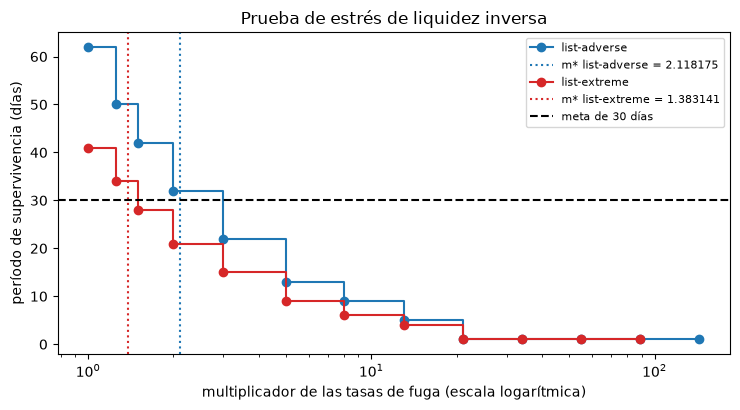

In [6]:
# Dibujar el período de supervivencia frente al multiplicador de las tasas de fuga, con la meta y los umbrales
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (base_id, (grid, days)), color in zip(curves.items(), ("tab:blue", "tab:red")):
    ax.step(grid, days, where="post", marker="o", color=color, label=base_id)
    m_star = solutions[base_id].multiplier
    ax.axvline(m_star, color=color, linestyle=":", label=f"m* {base_id} = {m_star}")
ax.axhline(target, color="black", linestyle="--", label="meta de 30 días")
ax.set_xscale("log")
ax.set_xlabel("multiplicador de las tasas de fuga (escala logarítmica)")
ax.set_ylabel("período de supervivencia (días)")
ax.set_title("Prueba de estrés de liquidez inversa")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Ambas curvas escalonadas caen con fuerza y luego se aplanan en el día 1. Bajo Adverso el banco dura 62 días con las tablas, 32 días con un multiplicador de 2 y 1 día desde 21; bajo Extremo parte en 41 y también llega a 1 día desde 21. Las verticales punteadas son la respuesta a la pregunta: la curva toca la línea de 30 días en 2,118175 para Adverso y 1,383141 para Extremo, así que la meta es un múltiplo pequeño de las tablas. El eje logarítmico estira los multiplicadores pequeños, donde está toda la acción, y la figura no dice si esas velocidades son plausibles, que es la pregunta del notebook siguiente.

### Paso 4: cuando el motor rechaza

Una meta que no queda acotada se rechaza con su razón, nunca se responde con un número. Hay tres razones: la meta no es menor que el horizonte (un período de supervivencia bajo ella no se distingue de sobrevivir el horizonte); el período de supervivencia base ya es menor o igual que la meta (no hay nada que invertir); o ningún multiplicador bajo el tope alcanza la meta. En este caso solo surgen las dos primeras: toda base llega al día 1 bajo su tope (las curvas del paso 2 terminan en 1). La base de corrida rápida del documento se rechaza por la primera razón: su horizonte es de 5 días y la meta es 30. La celda siguiente le pide al motor seis metas sobre la base Adversa (una exploración, no filas versionadas) y clasifica cada respuesta, y luego imprime el rechazo versionado de la corrida rápida en el idioma del notebook.

In [7]:
# Seis metas sobre la base Adversa: el motor responde con un multiplicador o rechaza con una de las tres razones
scenario, effective_cbc = built["list-adverse"]
reasons = (
    ("not below the horizon", "no es menor que el horizonte"),
    ("already at or below", "la supervivencia base ya es menor o igual a la meta"),
)
fallback = "ningún multiplicador bajo el tope la alcanza"
for days_target in (5, 31, 62, 124, 125, 200):
    answer = solve_multiplier(scenario, effective_cbc, days_target)
    if answer.status == "solved":
        print(f"meta {days_target:4d} | resuelta | m* = {answer.multiplier}")
    else:
        why = next((label for key, label in reasons if key in answer.reason), fallback)
        print(f"meta {days_target:4d} | rechazada: {why} | m* = {answer.multiplier}")

fast_run = bases["fast-run"]
print("corrida rápida, tal como se calculó:", status_words[fast_run["solved"]["status"]])
print(fast_run["solved"]["refusal_reason"]["es"])

meta    5 | resuelta | m* = 12.65873
meta   31 | resuelta | m* = 2.047593
meta   62 | rechazada: la supervivencia base ya es menor o igual a la meta | m* = None
meta  124 | rechazada: la supervivencia base ya es menor o igual a la meta | m* = None
meta  125 | rechazada: no es menor que el horizonte | m* = None
meta  200 | rechazada: no es menor que el horizonte | m* = None
corrida rápida, tal como se calculó: rechazado
El objetivo de 30 días no es menor que el horizonte de 5 días, así que un periodo de supervivencia bajo él no se puede separar de sobrevivir el horizonte: no existe un intervalo.


La celda siguiente le pide al solucionador todas las metas de 2 a 60 días de dos en dos y dibuja el multiplicador que cada una exige.

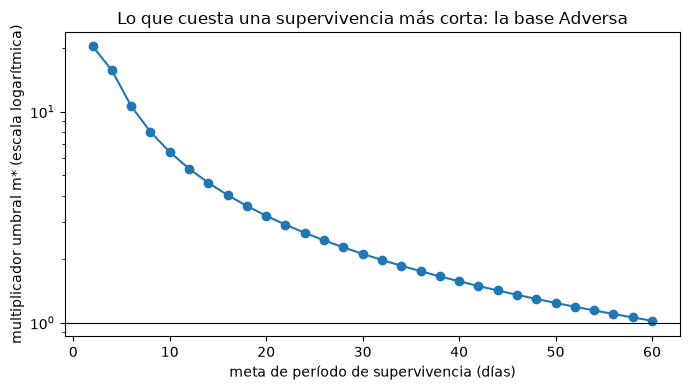

In [8]:
# El multiplicador umbral de la base Adversa para cada meta de 2 a 60 días
targets = list(range(2, 62, 2))
multipliers = [solve_multiplier(scenario, effective_cbc, t).multiplier for t in targets]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(targets, multipliers, marker="o")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_yscale("log")
ax.set_xlabel("meta de período de supervivencia (días)")
ax.set_ylabel("multiplicador umbral m* (escala logarítmica)")
ax.set_title("Lo que cuesta una supervivencia más corta: la base Adversa")
fig.tight_layout()
plt.show()

El multiplicador baja a medida que la meta se alarga y se acerca a 1 cuando la meta se acerca a la supervivencia base de 62 días, donde el motor deja de responder: en 62 la base ya cumple la meta. Una meta corta es cara, 12,65873 veces las tablas para 5 días frente a 2,047593 para 31 días, y la curva es más empinada en el extremo corto, así que la respuesta del notebook, 2,118175 para 30 días, queda en la parte plana. Todo punto es un umbral, no una estimación. La figura cubre solo las metas que el motor acepta; los rechazos de arriba son los que no se pueden dibujar.

### Paso 5: monotonía del período de supervivencia

El período de supervivencia no debe alargarse cuando el escenario se vuelve más severo (BCE, 2019, y el dosier de investigación). La prueba `liq.survival_monotone_in_severity` toma una lista de períodos de supervivencia ordenados del escenario más suave al más severo (con "sobrevive el horizonte" contado como más largo que cualquier día) y devuelve el mayor alargamiento a lo largo del orden, en días: verde si es cero. El documento la corre a lo largo de la curva de cada base. La celda siguiente la corre sobre las curvas del paso 2, entre las dos severidades de LiST (Adverso y luego Extremo), y sobre una violación plantada (el orden inverso) para mostrar cómo se ve un rojo.

In [9]:
# La prueba de monotonía a lo largo de cada curva, entre las dos severidades, y sobre una violación plantada
from riskvalidation.validation.liquidity import survival_monotone_in_severity

for base_id, (grid, days) in curves.items():
    along = survival_monotone_in_severity(days)
    print(base_id, "| a lo largo de la curva: mayor alargamiento (días):", along.statistic, LIGHTS[along.light.value])

at_tables = np.array([1.0])
base_survival = [survival_vs_multiplier(*built[b], at_tables)[0].day for b in ("list-adverse", "list-extreme")]
across = survival_monotone_in_severity(base_survival)
planted = survival_monotone_in_severity(base_survival[::-1])
print("entre severidades (Adverso, Extremo):", base_survival, "|", across.statistic, LIGHTS[across.light.value])
print("violación plantada (Ext., Adv.):", base_survival[::-1], "|", planted.statistic, LIGHTS[planted.light.value])

list-adverse | a lo largo de la curva: mayor alargamiento (días): 0.0 verde
list-extreme | a lo largo de la curva: mayor alargamiento (días): 0.0 verde
entre severidades (Adverso, Extremo): [62, 41] | 0.0 verde
violación plantada (Ext., Adv.): [41, 62] | 21.0 rojo


### Paso 6: el diagnóstico del acantilado

El último test del paquete que presentó el notebook 01 es el efecto acantilado entre el día 30 y el día 35 como proporción de los activos totales, $(\mathrm{NLP}(35) - \mathrm{NLP}(30)) / \mathrm{TA}$. `liq.cliff_effect_diagnostic` lo califica con dos convenciones del producto (ámbar bajo -0,01, rojo bajo -0,03), porque la nota del BCE no define ningún límite; es un diagnóstico de la forma de la posición, no un umbral regulatorio. La celda siguiente llama a la prueba sobre la serie NLP versionada de ambas bases.

In [10]:
# El diagnóstico del acantilado sobre la serie NLP versionada de las dos bases LiST
from riskvalidation.validation.liquidity import cliff_effect_diagnostic

for base_id in ("list-adverse", "list-extreme"):
    document = documents[base_id]["outputs"]
    nlp = np.array(document["path"]["ladder"]["nlp"])
    diagnostic = cliff_effect_diagnostic(nlp, document["balance_sheet"]["total_assets"])
    print(base_id, "| acantilado:", round(diagnostic.statistic, 6), "| semáforo:", LIGHTS[diagnostic.light.value])
    print("   cambio de la NLP (miles de millones de USD):", round(diagnostic.metric / 1e6, 3))

list-adverse | acantilado: -0.022246 | semáforo: ámbar
   cambio de la NLP (miles de millones de USD): -4.65
list-extreme | acantilado: -0.029776 | semáforo: ámbar
   cambio de la NLP (miles de millones de USD): -6.224


La última celda dibuja la NLP de ambas bases LiST con la ventana del acantilado entre el día 30 y el día 35 sombreada.

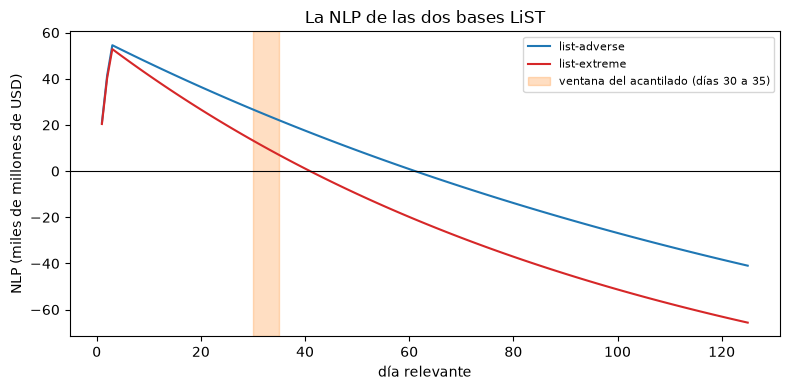

In [11]:
# Dibujar la NLP de ambas bases LiST con la ventana del acantilado entre el día 30 y el día 35
fig, ax = plt.subplots(figsize=(8, 4))
for base_id, color in (("list-adverse", "tab:blue"), ("list-extreme", "tab:red")):
    series = np.array(documents[base_id]["outputs"]["path"]["ladder"]["nlp"])
    ax.plot(np.arange(1, len(series) + 1), series / 1e6, color=color, label=base_id)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvspan(30, 35, color="tab:orange", alpha=0.25, label="ventana del acantilado (días 30 a 35)")
ax.set_xlabel("día relevante")
ax.set_ylabel("NLP (miles de millones de USD)")
ax.set_title("La NLP de las dos bases LiST")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Ambas posiciones pierden terreno a través de la ventana sombreada: 4,65 mil millones de USD en la base Adversa y 6,224 mil millones en la base Extrema, un efecto acantilado de -0,022246 y -0,029776 como proporción de los activos totales. Ambos son ámbar bajo las dos convenciones del producto, y la base Extrema queda justo sobre la línea roja de -0,03. Las dos curvas cruzan cero los días 62 y 41, bastante después de la ventana, así que el acantilado es una señal sobre la forma de la posición y no sobre el día de la quiebra. La figura muestra la forma; las calificaciones son convenciones del producto, pues la nota del BCE no define ningún límite.

## Resultados

**Respuesta:** Para que el banco sobreviva solo 30 días, las tasas de fuga deben ser 2,118175 veces más rápidas que la tabla LiST Adverso y 1,383141 veces más rápidas que la Extrema. Con esos multiplicadores el período de supervivencia es 30 días y un pelo por debajo es 31, así que son umbrales, no estimaciones, y la distancia es corta: duplicar las tasas Adversas ya lleva al banco de 62 días a 32. El motor rechaza las metas que no puede sustentar, 62 y 124 porque la base ya las cumple y 125 y 200 porque no son menores que el horizonte, y no devuelve ningún número para ellas.

- **CBC efectivo.** Con el CBC efectivo la prueba de identidad encuentra un mayor residuo de 7e-09 en la escalera Adversa y 3e-08 en la Extrema, verde.
- **Tope y curvas.** El tope es 145,234634 para Adverso y 93,876528 para Extremo. Bajo Adverso el período de supervivencia va de 62 días con $m = 1$ a 32 con 2, 5 con 13 y 1 desde 21; bajo Extremo de 41 a 21 con 2, 4 con 13 y 1 desde 21. Ambas curvas son no crecientes.
- **Los multiplicadores umbral.** El período de supervivencia con 2,118175 (Adverso) y 1,383141 (Extremo) es 30, y un pelo por debajo es 31. El viaje de ida y vuelta es verde con estadístico 0,0.
- **Rechazos.** Para metas de 5 y 31 días la base Adversa da multiplicadores de 12,65873 y 2,047593. Una meta de 62 o 124 días se rechaza porque el período de supervivencia base (62 días) ya es menor o igual a ella; una meta de 125 o 200 días se rechaza porque no es menor que el horizonte. La base de corrida rápida, tal como se calculó, se rechaza por esta última razón (una meta de 30 días frente a un horizonte de 5): no se inventa ningún número.
- **Monotonía.** A lo largo de cada curva el mayor alargamiento del período de supervivencia es 0,0 días, verde; entre las dos severidades ([62, 41]) es 0,0 y verde. El orden inverso plantado ([41, 62]) se alarga 21,0 días y es rojo, lo que muestra que la prueba puede fallar.
- **El diagnóstico del acantilado.** El efecto acantilado es -0,022246 en la base Adversa y -0,029776 en la base Extrema; ambos son ámbar bajo las dos convenciones del producto. La base Extrema queda justo sobre la línea roja de -0,03.

Lo que este notebook no muestra: si un multiplicador así es plausible frente a lo ocurrido en 2023 (esa es la pregunta de los notebooks 07 y 08), ni cómo cambiaría el multiplicador con otro calendario de CBC. Los multiplicadores son propiedades del comportamiento sintético del caso.

## Resumen

- La tensión inversa invierte la pregunta de un escenario: en vez de "¿cuánto sobrevive el banco con esta fuga?", "¿cuánto más rápida debe ser la fuga para que el banco dure solo una meta?".
- La respuesta es un multiplicador de las tasas diarias, limitado para que ninguna tasa pase de 1, y es un umbral: la meta se alcanza en él y no justo por debajo.
- El motor rechaza una meta con su razón en vez de devolver un número que no puede sustentar.
- Las pruebas del paquete verifican la identidad de la NLP, el viaje de ida y vuelta del solucionador y la monotonía del período de supervivencia, y cada una está versionada con la versión del motor que la calculó.

**Qué probar a continuación.** Cambia la meta del paso 4 a 45 y 90 días y mira cómo se mueve el multiplicador; luego sigue con el notebook 07.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Table 3.3 (the run-off rates of the bases). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10 (stress tests in short-term and protracted, institution-specific and market-wide scenarios). https://www.bis.org/publ/bcbs144.htm